# Housing Price Data Analysis using Python

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("Mumbai House Prices.csv")
data.head()

,bhk,type,locality,area,price,price_unit,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,2.50,Cr,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,L,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,1.73,Cr,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,L,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,94.11,L,Mira Road East,Under Construction,New


In [3]:
print("\nDataset Information:")
print(data.info())

print("\nDataset Description:")
print(data.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76038 entries, 0 to 76037
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   bhk         76038 non-null  int64  
 1   type        76038 non-null  object 
 2   locality    76038 non-null  object 
 3   area        76038 non-null  int64  
 4   price       76038 non-null  float64
 5   price_unit  76038 non-null  object 
 6   region      76038 non-null  object 
 7   status      76038 non-null  object 
 8   age         76038 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 5.2+ MB
None

Dataset Description:
                bhk          area        price
count  76038.000000  76038.000000  76038.00000
mean       2.015111   1024.536850     29.38227
std        0.922754    670.276165     32.90345
min        1.000000    127.000000      1.00000
25%        1.000000    640.000000      1.75000
50%        2.000000    872.000000      5.50000
7

In [4]:
print("\nMissing values:")
print(data.isnull().sum())

data = data.dropna()


Missing values:
bhk           0
type          0
locality      0
area          0
price         0
price_unit    0
region        0
status        0
age           0
dtype: int64


In [5]:
# Convert Crore values to Lakhs
data.loc[data['price_unit'] == 'Cr', 'price'] = data['price'] * 100

# Now all prices are in Lakhs
data['price_unit'] = 'Lakhs'

data[['price','price_unit']].head()


,price,price_unit
0,250.00,Lakhs
1,52.51,Lakhs
2,173.00,Lakhs
3,59.98,Lakhs
4,94.11,Lakhs


In [6]:
data = data.drop(columns=['price_unit'])
data.head()
data.to_csv("cleaned_mumbai_housing.csv", index=False)

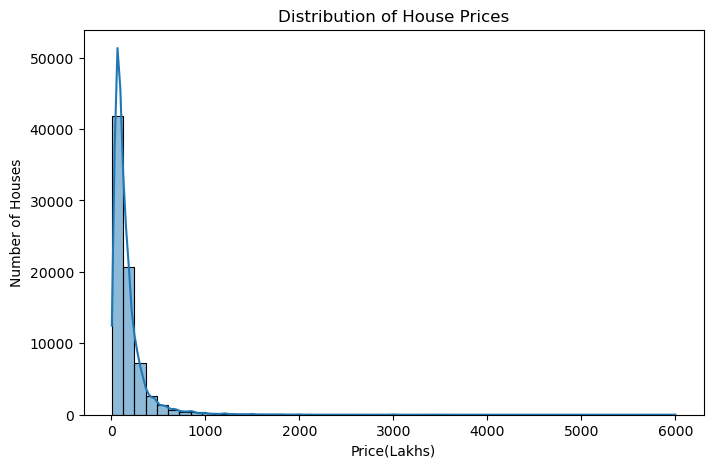

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(data['price'], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price(Lakhs)")
plt.ylabel("Number of Houses")

plt.show()

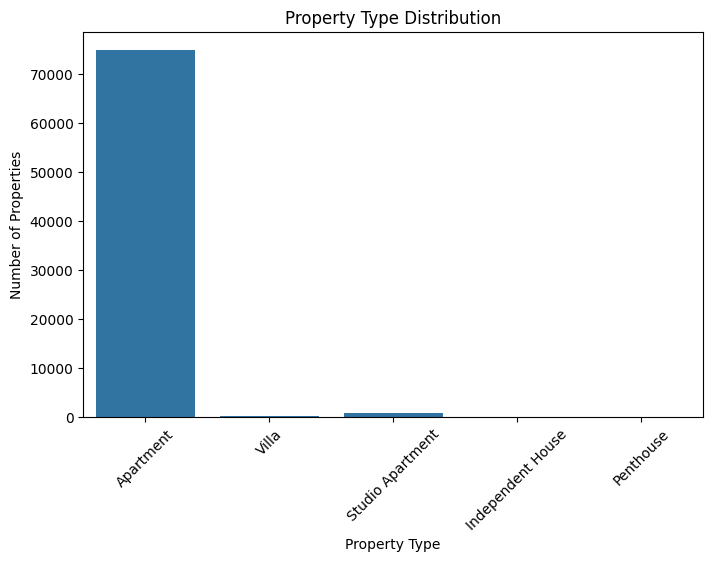

In [31]:
plt.figure(figsize=(8,5))
sns.countplot(x='type', data=data)

plt.title("Property Type Distribution")
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")

plt.xticks(rotation=45)

plt.show()

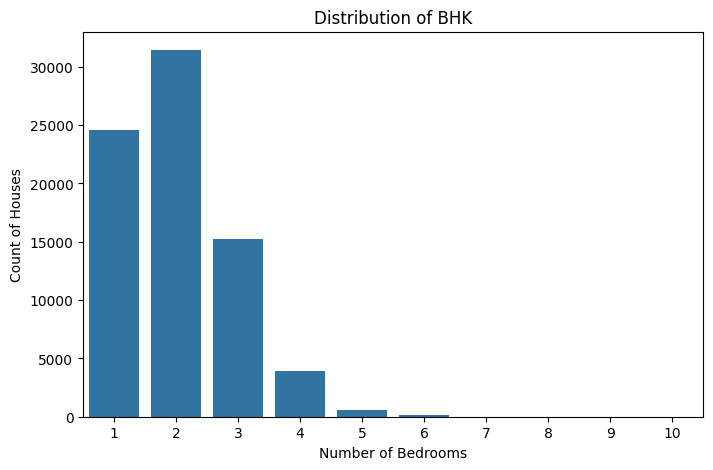

In [32]:
plt.figure(figsize=(8,5))
sns.countplot(x='bhk', data=data)

plt.title("Distribution of BHK")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Count of Houses")

plt.show()

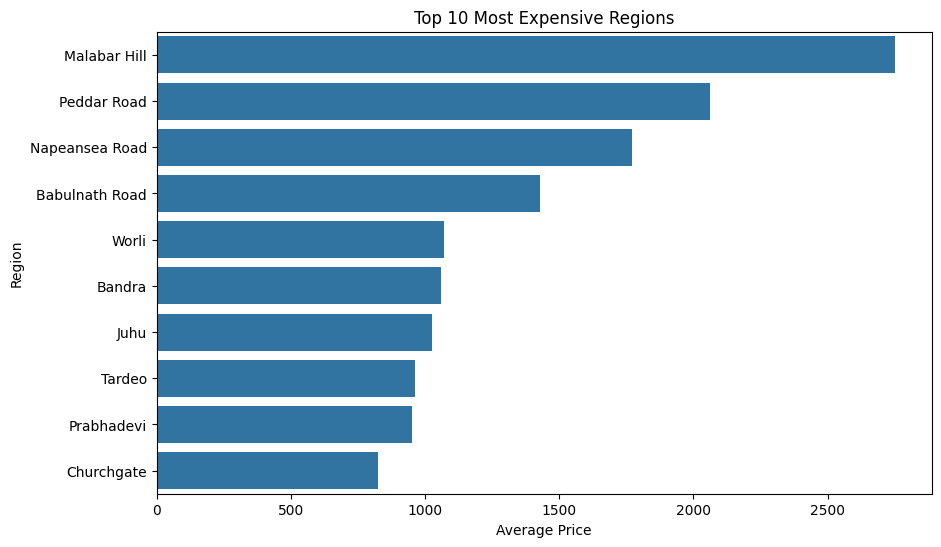

In [33]:
region_price = data.groupby("region")["price"].mean().sort_values(ascending=False)

top_regions = region_price.head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_regions.values, y=top_regions.index)

plt.title("Top 10 Most Expensive Regions")
plt.xlabel("Average Price")
plt.ylabel("Region")

plt.show()

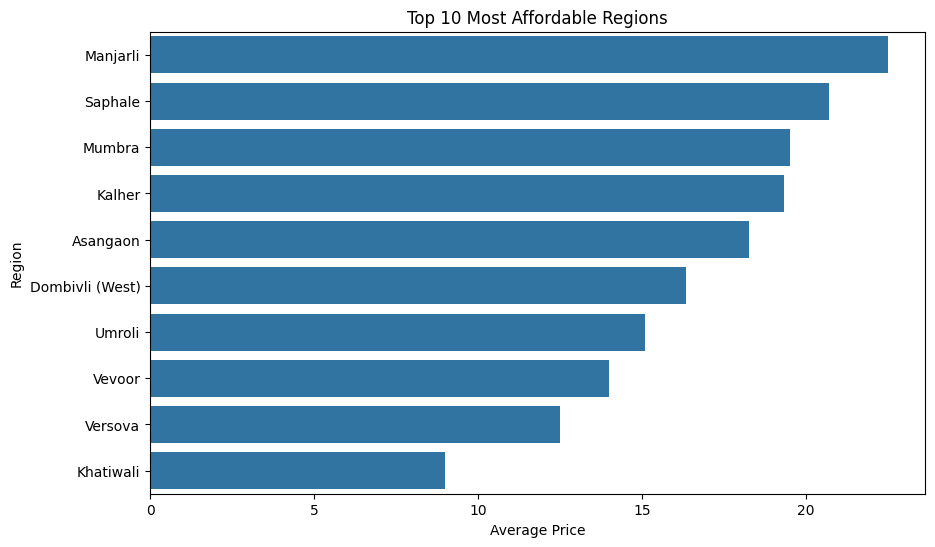

In [33]:
cheap_regions = region_price.tail(10)

plt.figure(figsize=(10,6))
sns.barplot(x=cheap_regions.values, y=cheap_regions.index)

plt.title("Top 10 Most Affordable Regions")
plt.xlabel("Average Price")
plt.ylabel("Region")

plt.show()

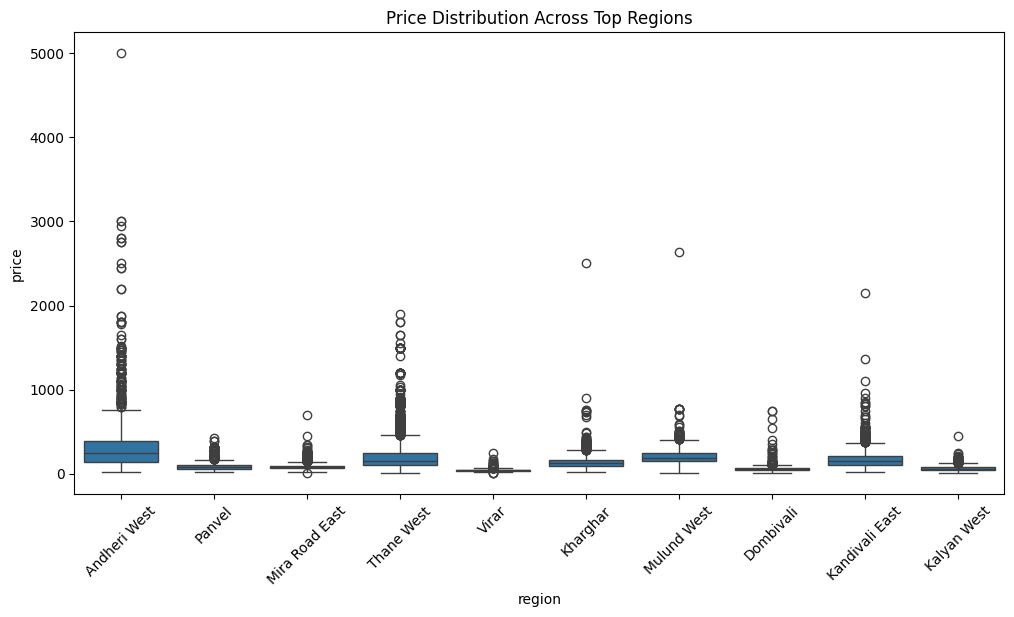

In [34]:
top_regions_list = data['region'].value_counts().head(10).index

filtered = data[data['region'].isin(top_regions_list)]

plt.figure(figsize=(12,6))

sns.boxplot(x='region', y='price', data=filtered)

plt.xticks(rotation=45)

plt.title("Price Distribution Across Top Regions")

plt.show()

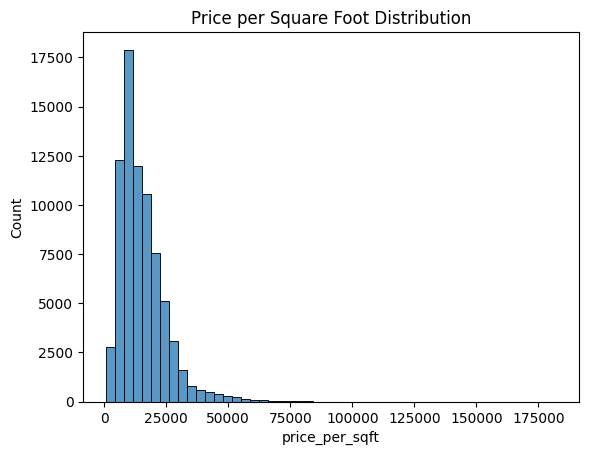

In [35]:
data['price_per_sqft'] = data['price'] *100000/ data['area']

sns.histplot(data['price_per_sqft'], bins=50)
plt.title("Price per Square Foot Distribution")
plt.show()

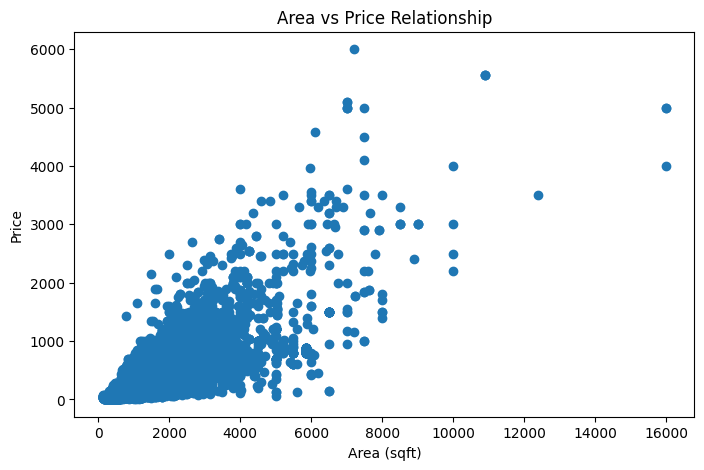

In [36]:
plt.figure(figsize=(8,5))

plt.scatter(data['area'], data['price'])

plt.xlabel("Area (sqft)")
plt.ylabel("Price")
plt.title("Area vs Price Relationship")

plt.show()

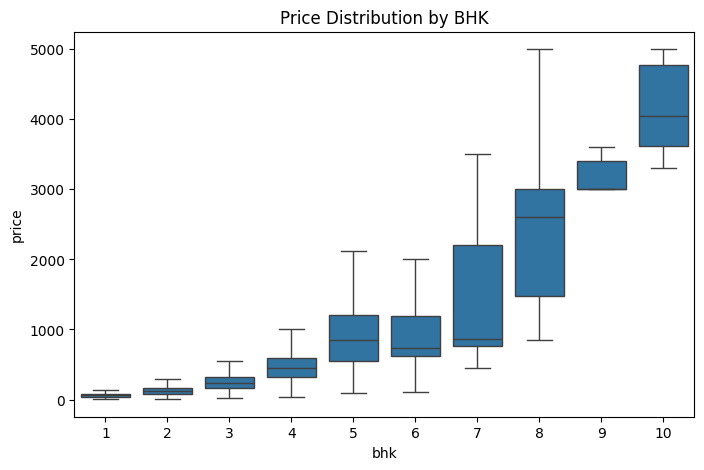

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(x='bhk', y='price', data=data,showfliers=False)

plt.title("Price Distribution by BHK")

plt.show()

In [8]:
# Calculate price per square foot
data['price_per_sqft'] = data['price'] / data['area']

# View new column
data[['price','area','price_per_sqft']].head()

,price,area,price_per_sqft
0,250.00,685,0.364964
1,52.51,640,0.082047
2,173.00,610,0.283607
3,59.98,876,0.068470
4,94.11,659,0.142807


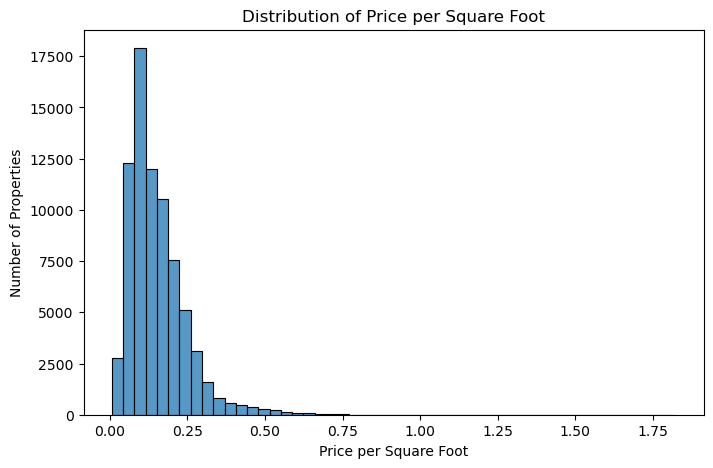

In [9]:
plt.figure(figsize=(8,5))

sns.histplot(data['price_per_sqft'], bins=50)

plt.title("Distribution of Price per Square Foot")
plt.xlabel("Price per Square Foot")
plt.ylabel("Number of Properties")

plt.show()

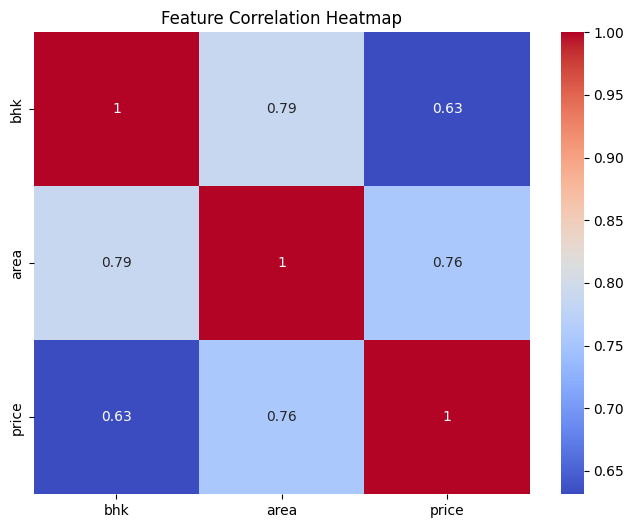

In [10]:
plt.figure(figsize=(8,6))

sns.heatmap(data.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Feature Correlation Heatmap")

plt.show()